# Deepfake Image Detection using EfficientNet-B0

This notebook presents the complete workflow for a binary deepfake-image classification project:

1. Dataset inspection and quality checks
2. Augmentation and duplicate analysis
3. Leakage-safe train/validation/test splitting
4. EfficientNet-B0 training
5. Test-set evaluation
6. Error analysis and robustness testing

**Classes:** `Real` and `Fake`  
**Model:** Pretrained EfficientNet-B0 with a 2-class classification head


## 1. Environment and Dataset Setup


In [5]:
import os
from google.colab import drive

if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/Deepfake_Detection"

if os.path.exists(PROJECT_DIR):
    print("Directory found! Files:")
    print(os.listdir(PROJECT_DIR))
else:
    print(f"Error: The directory {PROJECT_DIR} does not exist.")
    print("Please make sure you have created this folder in your Google Drive.")

Mounted at /content/drive
Directory found! Files:
['raw_dataset.zip', 'splits', 'DeepFake_Face_Detection.ipynb', 'best_efficientnet_b0.pth']


In [6]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    print("No GPU detected.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA L4
VRAM: 22.03 GB


In [7]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Dataset Inspection

In [8]:
import zipfile
import pandas as pd
import os
import io

ZIP_PATH = os.path.join(PROJECT_DIR, "raw_dataset.zip")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    csv_path = "Final Dataset/dataset.csv"

    with zip_ref.open(csv_path) as f:
        df = pd.read_csv(f)

print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))

print("\nData types:")
print(df.dtypes)

Shape: (12890, 2)

Columns:
['path', 'label']

First 10 rows:


,path,label
0,/kaggle/input/stylegan-and-stylegan2-combined-...,Real
1,/kaggle/input/stylegan-and-stylegan2-combined-...,Real
2,/kaggle/input/stylegan-and-stylegan2-combined-...,Fake
3,/kaggle/input/stylegan-and-stylegan2-combined-...,Real
4,/kaggle/input/stylegan-and-stylegan2-combined-...,Real
5,/kaggle/input/stylegan-and-stylegan2-combined-...,Fake
6,/kaggle/input/stylegan-and-stylegan2-combined-...,Real
7,/kaggle/input/stylegan-and-stylegan2-combined-...,Fake
8,/kaggle/input/stylegan-and-stylegan2-combined-...,Real
9,/kaggle/input/stylegan-and-stylegan2-combined-...,Real



Data types:
path     object
label    object
dtype: object


In [9]:
import pandas as pd
import re

# Class distribution
print("CLASS DISTRIBUTION")
print(df["label"].value_counts())
print("\nPercentage:")
print((df["label"].value_counts(normalize=True) * 100).round(2))


# Analyze augmented filenames
df["filename"] = df["path"].str.split("/").str[-1]

df["is_augmented"] = df["filename"].str.contains(
    r"_aug_\d+",
    regex=True
)

print("\nAUGMENTATION DISTRIBUTION")
print(df.groupby(["label", "is_augmented"]).size())


print("\nAugmented images:")
print(df["is_augmented"].value_counts())

CLASS DISTRIBUTION
label
Fake    7000
Real    5890
Name: count, dtype: int64

Percentage:
label
Fake    54.31
Real    45.69
Name: proportion, dtype: float64

AUGMENTATION DISTRIBUTION
label  is_augmented
Fake   False           3500
       True            3500
Real   False           2945
       True            2945
dtype: int64

Augmented images:
is_augmented
True     6445
False    6445
Name: count, dtype: int64


In [10]:
def get_base_name(filename):
    return re.sub(r"_aug_\d+(?=\.[^.]+$)", "", filename)

df["base_name"] = df["filename"].apply(get_base_name)

print("Unique underlying filenames:")
print(df["base_name"].nunique())

print("\nImages per underlying filename:")
print(df.groupby("base_name").size().value_counts().sort_index())

Unique underlying filenames:
7734

Images per underlying filename:
1    6445
5    1289
Name: count, dtype: int64


## 3. Dataset Extraction and Visual Inspection

In [11]:
import os
import zipfile
import shutil

ZIP_PATH = "/content/drive/MyDrive/Deepfake_Detection/raw_dataset.zip"
EXTRACT_DIR = "/content/deepfake_dataset"

# Remove previous extraction if it exists
if os.path.exists(EXTRACT_DIR):
    shutil.rmtree(EXTRACT_DIR)

os.makedirs(EXTRACT_DIR, exist_ok=True)

print("Extracting dataset...")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction complete!")

Extracting dataset...
Extraction complete!


In [12]:
from PIL import Image
import matplotlib.pyplot as plt
import random
import os

FAKE_DIR = os.path.join(
    EXTRACT_DIR,
    "Final Dataset",
    "Fake"
)

REAL_DIR = os.path.join(
    EXTRACT_DIR,
    "Final Dataset",
    "Real"
)

fake_images = [
    os.path.join(FAKE_DIR, f)
    for f in os.listdir(FAKE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

real_images = [
    os.path.join(REAL_DIR, f)
    for f in os.listdir(REAL_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Fake:", len(fake_images))
print("Real:", len(real_images))

Fake: 7000
Real: 5890


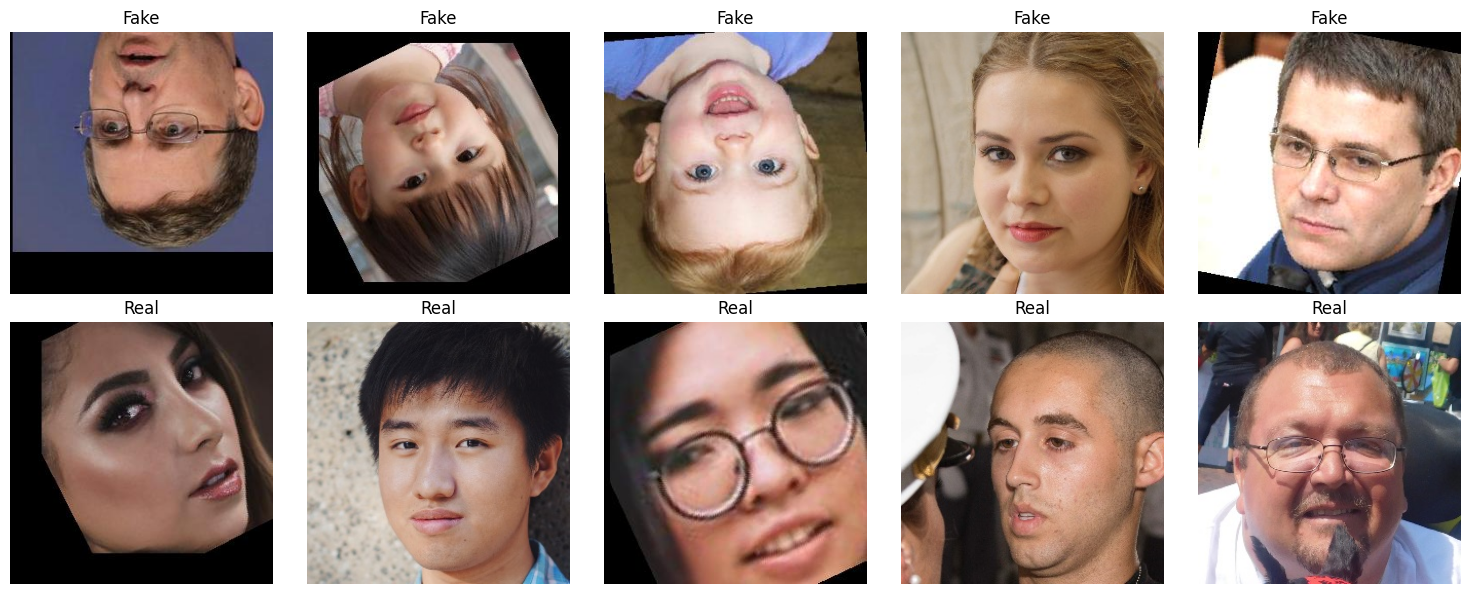

In [46]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):
    fake_path = random.choice(fake_images)
    real_path = random.choice(real_images)

    fake_img = Image.open(fake_path)
    real_img = Image.open(real_path)

    axes[0, i].imshow(fake_img)
    axes[0, i].set_title("Fake")
    axes[0, i].axis("off")

    axes[1, i].imshow(real_img)
    axes[1, i].set_title("Real")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [14]:
from PIL import Image
import os
from collections import Counter
import pandas as pd

def inspect_images(image_paths):
    records = []
    corrupt = []

    for path in image_paths:
        try:
            with Image.open(path) as img:
                records.append({
                    "path": path,
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                    "format": img.format,
                    "aspect_ratio": round(img.width / img.height, 3)
                })
        except Exception as e:
            corrupt.append((path, str(e)))

    return pd.DataFrame(records), corrupt


fake_df, fake_corrupt = inspect_images(fake_images)
real_df, real_corrupt = inspect_images(real_images)

fake_df["label"] = "Fake"
real_df["label"] = "Real"

image_df = pd.concat([fake_df, real_df], ignore_index=True)

print("Total successfully inspected:", len(image_df))
print("Corrupt Fake images:", len(fake_corrupt))
print("Corrupt Real images:", len(real_corrupt))

Total successfully inspected: 12890
Corrupt Fake images: 0
Corrupt Real images: 0


In [15]:
print("\nIMAGE MODES")
print(pd.crosstab(image_df["label"], image_df["mode"]))

print("\nIMAGE FORMATS")
print(pd.crosstab(image_df["label"], image_df["format"]))

print("\nCOMMON DIMENSIONS")
print(
    image_df.groupby(["label", "width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(20)
)


IMAGE MODES
mode    RGB
label      
Fake   7000
Real   5890

IMAGE FORMATS
format  JPEG
label       
Fake    7000
Real    5890

COMMON DIMENSIONS
label  width  height
Fake   256    256       3561
Real   256    256       2997
Fake   300    300        905
Real   300    300        753
Fake   272    272         76
       280    280         76
       298    298         70
       284    284         68
Real   260    260         68
Fake   270    270         68
       250    250         67
       268    268         67
       292    292         65
       296    296         64
       274    274         64
       288    288         64
       244    244         63
Real   262    262         63
       292    292         62
       282    282         61
dtype: int64


In [16]:
print("\nDIMENSION SUMMARY")

display(
    image_df.groupby("label")[["width", "height", "aspect_ratio"]]
    .agg(["min", "max", "mean", "median"])
)


DIMENSION SUMMARY


width                         height                          \
        min  max        mean median    min  max        mean median   
label                                                                
Fake    196  360  270.565143  256.0    196  360  270.565143  256.0   
Real    196  360  270.674703  256.0    196  360  270.674703  256.0   

      aspect_ratio                   
               min  max mean median  
label                                
Fake           1.0  1.0  1.0    1.0  
Real           1.0  1.0  1.0    1.0

## 4. Duplicate and Data-Leakage Checks

In [17]:
import hashlib
from collections import defaultdict
import os

def md5_file(path, chunk_size=8192):
    md5 = hashlib.md5()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            md5.update(chunk)

    return md5.hexdigest()


hash_to_files = defaultdict(list)

all_images = fake_images + real_images

print("Calculating image hashes...")

for i, path in enumerate(all_images):
    file_hash = md5_file(path)
    hash_to_files[file_hash].append(path)

    if (i + 1) % 1000 == 0:
        print(f"Processed {i + 1}/{len(all_images)}")

duplicate_groups = {
    h: paths
    for h, paths in hash_to_files.items()
    if len(paths) > 1
}

print("\nUnique hashes:", len(hash_to_files))
print("Duplicate groups:", len(duplicate_groups))

duplicate_images = sum(
    len(paths) for paths in duplicate_groups.values()
)

print("Images involved in duplicate groups:", duplicate_images)

Calculating image hashes...
Processed 1000/12890
Processed 2000/12890
Processed 3000/12890
Processed 4000/12890
Processed 5000/12890
Processed 6000/12890
Processed 7000/12890
Processed 8000/12890
Processed 9000/12890
Processed 10000/12890
Processed 11000/12890
Processed 12000/12890

Unique hashes: 12886
Duplicate groups: 4
Images involved in duplicate groups: 8


In [18]:
# Check whether any base image appears with multiple labels

label_counts = df.groupby("base_name")["label"].nunique()

conflicting_groups = label_counts[label_counts > 1]

print("Total groups:", len(label_counts))
print("Groups with conflicting labels:", len(conflicting_groups))

if len(conflicting_groups) > 0:
    print("\nWARNING: Conflicting groups found:")
    print(conflicting_groups)
else:
    print("✅ Every image group has exactly one label.")

Total groups: 7734
Groups with conflicting labels: 0
✅ Every image group has exactly one label.


In [19]:
group_df = (
    df.groupby("base_name")
      .agg(
          label=("label", "first"),
          group_size=("filename", "count")
      )
      .reset_index()
)

print("Number of groups:", len(group_df))

print("\nGroups by label:")
print(group_df["label"].value_counts())

print("\nGroup sizes:")
print(group_df["group_size"].value_counts().sort_index())

Number of groups: 7734

Groups by label:
label
Fake    4200
Real    3534
Name: count, dtype: int64

Group sizes:
group_size
1    6445
5    1289
Name: count, dtype: int64


## 5. Group-Aware Train / Validation / Test Split

In [20]:
from sklearn.model_selection import train_test_split

# First split:
# 70% train
# 30% temporary (validation + test)

train_groups, temp_groups = train_test_split(
    group_df,
    test_size=0.30,
    random_state=42,
    stratify=group_df["label"]
)

# Second split:
# 15% validation
# 15% test

val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.50,
    random_state=42,
    stratify=temp_groups["label"]
)

print("Train groups:", len(train_groups))
print("Validation groups:", len(val_groups))
print("Test groups:", len(test_groups))

Train groups: 5413
Validation groups: 1160
Test groups: 1161


In [21]:
train_base_names = set(train_groups["base_name"])
val_base_names = set(val_groups["base_name"])
test_base_names = set(test_groups["base_name"])

def assign_split(base_name):
    if base_name in train_base_names:
        return "train"
    elif base_name in val_base_names:
        return "val"
    elif base_name in test_base_names:
        return "test"
    else:
        return None

df["split"] = df["base_name"].apply(assign_split)

print(df["split"].value_counts())

split
train    9085
test     1905
val      1900
Name: count, dtype: int64


In [22]:
train_set = set(
    df[df["split"] == "train"]["base_name"]
)

val_set = set(
    df[df["split"] == "val"]["base_name"]
)

test_set = set(
    df[df["split"] == "test"]["base_name"]
)

print("Train ∩ Validation:", len(train_set & val_set))
print("Train ∩ Test:", len(train_set & test_set))
print("Validation ∩ Test:", len(val_set & test_set))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [23]:
print("\nIMAGE COUNTS")
print(
    pd.crosstab(
        df["split"],
        df["label"]
    )
)

print("\nPERCENTAGES")
print(
    pd.crosstab(
        df["split"],
        df["label"],
        normalize="index"
    ).round(4) * 100
)


IMAGE COUNTS
label  Fake  Real
split            
test   1006   899
train  4980  4105
val    1014   886

PERCENTAGES
label   Fake   Real
split              
test   52.81  47.19
train  54.82  45.18
val    53.37  46.63


In [24]:
SPLIT_DIR = "/content/drive/MyDrive/Deepfake_Detection/splits"

os.makedirs(SPLIT_DIR, exist_ok=True)

df[
    ["path", "filename", "base_name", "label", "split"]
].to_csv(
    os.path.join(SPLIT_DIR, "dataset_split.csv"),
    index=False
)

print("Saved:", os.path.join(SPLIT_DIR, "dataset_split.csv"))

Saved: /content/drive/MyDrive/Deepfake_Detection/splits/dataset_split.csv


In [25]:
import os
import pandas as pd

SPLIT_CSV = "/content/drive/MyDrive/Deepfake_Detection/splits/dataset_split.csv"

df = pd.read_csv(SPLIT_CSV)

DATASET_ROOT = "/content/deepfake_dataset/Final Dataset"

df["local_path"] = df.apply(
    lambda row: os.path.join(
        DATASET_ROOT,
        row["label"],
        row["filename"]
    ),
    axis=1
)

print(df[["filename", "label", "split", "local_path"]].head())

             filename label  split  \
0  real_378_aug_1.jpg  Real  train   
1  real_283_aug_1.jpg  Real  train   
2      2TSVE42PCX.jpg  Fake   test   
3  real_213_aug_3.jpg  Real    val   
4           01149.jpg  Real  train   

                                          local_path  
0  /content/deepfake_dataset/Final Dataset/Real/r...  
1  /content/deepfake_dataset/Final Dataset/Real/r...  
2  /content/deepfake_dataset/Final Dataset/Fake/2...  
3  /content/deepfake_dataset/Final Dataset/Real/r...  
4  /content/deepfake_dataset/Final Dataset/Real/0...  


In [26]:
print(
    "Missing files:",
    (~df["local_path"].apply(os.path.exists)).sum()
)

Missing files: 0


## 6. PyTorch Data Pipeline

In [27]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

        self.label_map = {
            "Real": 0,
            "Fake": 1
        }

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        row = self.data.iloc[index]

        image = Image.open(row["local_path"]).convert("RGB")

        label = self.label_map[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

In [28]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(15),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [29]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [30]:
train_df = df[df["split"] == "train"].copy()
val_df   = df[df["split"] == "val"].copy()
test_df  = df[df["split"] == "test"].copy()

train_dataset = DeepfakeDataset(
    train_df,
    transform=train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    transform=eval_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    transform=eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 9085
Validation: 1900
Test: 1905


In [31]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

## 7. EfficientNet-B0 Model Setup

In [32]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

Device: cuda
GPU: NVIDIA L4
VRAM: 22.03 GB


In [33]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load pretrained EfficientNet-B0
weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

print(model)

print("Architecture: EfficientNet-B0")
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 231MB/s]

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActivat

In [34]:
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    2
)

In [35]:
model = model.to(device)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [36]:
criterion = nn.CrossEntropyLoss()

In [37]:
import torch.optim as optim

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [38]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

In [39]:
scaler = torch.amp.GradScaler("cuda")

## 8. Model Training

In [40]:
import torch
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

EPOCHS = 10

best_val_loss = float("inf")
best_model_path = "/content/drive/MyDrive/Deepfake_Detection/best_efficientnet_b0.pth"

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": []
}

for epoch in range(EPOCHS):

    # =========================
    # TRAINING
    # =========================
    model.train()

    running_train_loss = 0.0
    train_samples = 0

    for images, labels in train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):

            outputs = model(images)

            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)

        running_train_loss += loss.item() * batch_size
        train_samples += batch_size

    train_loss = running_train_loss / train_samples


    # =========================
    # VALIDATION
    # =========================
    model.eval()

    running_val_loss = 0.0
    val_samples = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):

                outputs = model(images)

                loss = criterion(outputs, labels)

            predictions = torch.argmax(outputs, dim=1)

            batch_size = images.size(0)

            running_val_loss += loss.item() * batch_size
            val_samples += batch_size

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    val_loss = running_val_loss / val_samples

    val_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    val_precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    val_recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    val_f1 = f1_score(
        all_labels,
        all_predictions,
        zero_division=0
    )


    # =========================
    # LEARNING RATE SCHEDULER
    # =========================
    scheduler.step(val_loss)


    # =========================
    # SAVE BEST MODEL
    # =========================
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "val_f1": val_f1
        }, best_model_path)

        best_marker = " ⭐ BEST"

    else:
        best_marker = ""


    # =========================
    # STORE HISTORY
    # =========================
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["val_precision"].append(val_precision)
    history["val_recall"].append(val_recall)
    history["val_f1"].append(val_f1)


    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"LR: {current_lr:.2e}"
        f"{best_marker}"
    )

Epoch [1/10] | Train Loss: 0.3456 | Val Loss: 0.2133 | Val Acc: 0.9058 | Val F1: 0.9172 | LR: 1.00e-04 ⭐ BEST
Epoch [2/10] | Train Loss: 0.1487 | Val Loss: 0.1136 | Val Acc: 0.9542 | Val F1: 0.9568 | LR: 1.00e-04 ⭐ BEST
Epoch [3/10] | Train Loss: 0.0905 | Val Loss: 0.1046 | Val Acc: 0.9605 | Val F1: 0.9631 | LR: 1.00e-04 ⭐ BEST
Epoch [4/10] | Train Loss: 0.0664 | Val Loss: 0.0932 | Val Acc: 0.9663 | Val F1: 0.9687 | LR: 1.00e-04 ⭐ BEST
Epoch [5/10] | Train Loss: 0.0560 | Val Loss: 0.0847 | Val Acc: 0.9705 | Val F1: 0.9728 | LR: 1.00e-04 ⭐ BEST
Epoch [6/10] | Train Loss: 0.0346 | Val Loss: 0.0925 | Val Acc: 0.9732 | Val F1: 0.9749 | LR: 1.00e-04
Epoch [7/10] | Train Loss: 0.0398 | Val Loss: 0.0764 | Val Acc: 0.9768 | Val F1: 0.9784 | LR: 1.00e-04 ⭐ BEST
Epoch [8/10] | Train Loss: 0.0273 | Val Loss: 0.0916 | Val Acc: 0.9737 | Val F1: 0.9757 | LR: 1.00e-04
Epoch [9/10] | Train Loss: 0.0259 | Val Loss: 0.0960 | Val Acc: 0.9753 | Val F1: 0.9771 | LR: 1.00e-04
Epoch [10/10] | Train Loss: 0.0

## 9. Best Checkpoint and Test Evaluation

In [41]:
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Load best checkpoint
checkpoint = torch.load(
    best_model_path,
    map_location=device
)

model.load_state_dict(checkpoint["model_state_dict"])

print("Best checkpoint loaded.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint validation loss:", checkpoint["val_loss"])
print("Checkpoint validation accuracy:", checkpoint["val_accuracy"])
print("Checkpoint validation F1:", checkpoint["val_f1"])

Best checkpoint loaded.
Checkpoint epoch: 7
Checkpoint validation loss: 0.07644551830856423
Checkpoint validation accuracy: 0.9768421052631578
Checkpoint validation F1: 0.9784313725490196


In [42]:
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(
            probabilities[:, 1].float().cpu().numpy()
        )

# Metrics
test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

test_precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

test_auc = roc_auc_score(
    all_labels,
    all_probabilities
)

print("\n===== TEST RESULTS =====")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1 Score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_auc:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Real", "Fake"],
        digits=4
    )
)

print("\n===== CONFUSION MATRIX =====")
print(
    confusion_matrix(
        all_labels,
        all_predictions
    )
)


===== TEST RESULTS =====
Accuracy : 0.9795
Precision: 0.9792
Recall   : 0.9821
F1 Score : 0.9806
ROC-AUC  : 0.9979

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

        Real     0.9799    0.9766    0.9783       899
        Fake     0.9792    0.9821    0.9806      1006

    accuracy                         0.9795      1905
   macro avg     0.9795    0.9794    0.9795      1905
weighted avg     0.9795    0.9795    0.9795      1905


===== CONFUSION MATRIX =====
[[878  21]
 [ 18 988]]


## 10. Performance Visualizations

<Figure size 700x600 with 0 Axes>

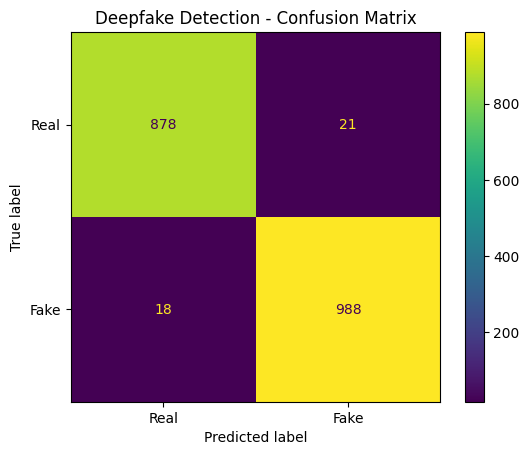

<Figure size 700x600 with 0 Axes>

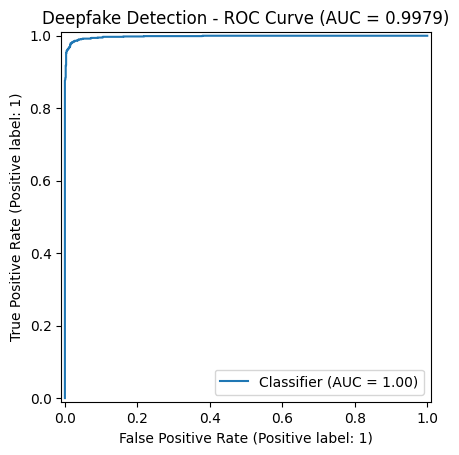

In [43]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# =========================
# CONFUSION MATRIX
# =========================

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
)

disp.plot(values_format="d")

plt.title("Deepfake Detection - Confusion Matrix")
plt.show()


# =========================
# ROC CURVE
# =========================

plt.figure(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    all_labels,
    all_probabilities
)

plt.title(
    f"Deepfake Detection - ROC Curve "
    f"(AUC = {test_auc:.4f})"
)

plt.show()

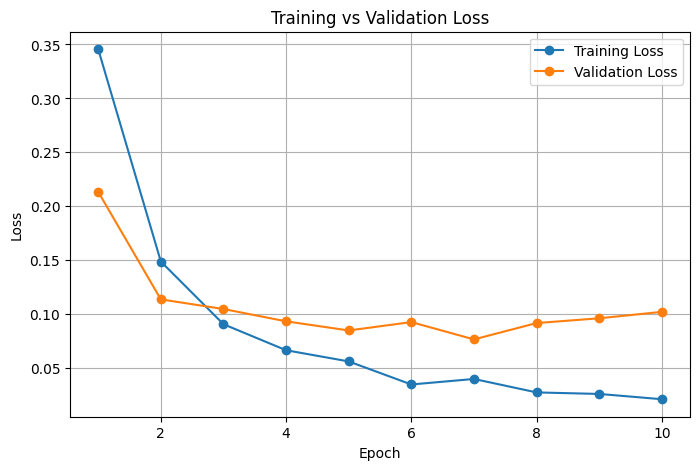

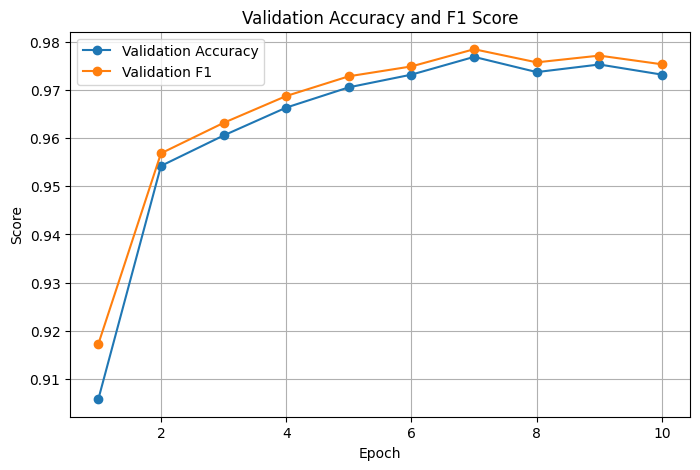

In [44]:
epochs = range(1, len(history["train_loss"]) + 1)

# =========================
# LOSS CURVE
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# =========================
# METRICS CURVE
# =========================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.plot(
    epochs,
    history["val_f1"],
    marker="o",
    label="Validation F1")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Accuracy and F1 Score")
plt.legend()
plt.grid(True)
plt.show()

## 11. Error Analysis

In [47]:
# Get the test portion of the split metadata
test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

# Create prediction results
test_results = test_df[[
    "path",
    "filename",
    "base_name",
    "label"
]].copy()

# Convert numeric labels back to class names
label_names = {
    0: "Real",
    1: "Fake"
}

test_results["true_label"] = [
    label_names[x] for x in all_labels
]

test_results["predicted_label"] = [
    label_names[x] for x in all_predictions
]

# Probability of each class
test_results["real_probability"] = [
    1 - p for p in all_probabilities
]

test_results["fake_probability"] = all_probabilities

# Whether prediction was correct
test_results["correct"] = (
    test_results["true_label"] ==
    test_results["predicted_label"]
)

print("Test results shape:", test_results.shape)

print("\nColumns:")
print(test_results.columns.tolist())

print("\nCorrect / Incorrect:")
print(test_results["correct"].value_counts())

print("\nMisclassified images:")
print((~test_results["correct"]).sum())

Test results shape: (1905, 9)

Columns:
['path', 'filename', 'base_name', 'label', 'true_label', 'predicted_label', 'real_probability', 'fake_probability', 'correct']

Correct / Incorrect:
correct
True     1866
False      39
Name: count, dtype: int64

Misclassified images:
39


In [48]:
# Summarize test-set misclassifications
errors = test_results[test_results["correct"] == False].copy()

real_to_fake = errors[
    (errors["true_label"] == "Real") &
    (errors["predicted_label"] == "Fake")
]

fake_to_real = errors[
    (errors["true_label"] == "Fake") &
    (errors["predicted_label"] == "Real")
]

print("===== ERROR BREAKDOWN =====")
print(f"Total errors : {len(errors)}")
print(f"Real → Fake  : {len(real_to_fake)}")
print(f"Fake → Real  : {len(fake_to_real)}")


===== ERROR BREAKDOWN =====
Total errors : 39
Real → Fake  : 21
Fake → Real  : 18


In [49]:
import pandas as pd

def confidence_summary(df, name):
    # Confidence = probability of the class the model predicted
    confidence = df[[
        "real_probability",
        "fake_probability"
    ]].max(axis=1)

    print(f"\n===== {name} =====")
    print(f"Count          : {len(df)}")
    print(f"Mean confidence: {confidence.mean():.4f}")
    print(f"Median         : {confidence.median():.4f}")
    print(f"Minimum        : {confidence.min():.4f}")
    print(f"Maximum        : {confidence.max():.4f}")

    print("\nConfidence distribution:")
    print(
        pd.cut(
            confidence,
            bins=[0.5, 0.6, 0.8, 0.9, 0.95, 1.0],
            labels=[
                "50-60%",
                "60-80%",
                "80-90%",
                "90-95%",
                "95-100%"
            ],
            include_lowest=True
        ).value_counts().sort_index()
    )


confidence_summary(errors, "ALL MISCLASSIFICATIONS")
confidence_summary(real_to_fake, "REAL → FAKE")
confidence_summary(fake_to_real, "FAKE → REAL")


===== ALL MISCLASSIFICATIONS =====
Count          : 39
Mean confidence: 0.7932
Median         : 0.8314
Minimum        : 0.5000
Maximum        : 0.9989

Confidence distribution:
50-60%      7
60-80%     10
80-90%      8
90-95%      5
95-100%     9
Name: count, dtype: int64

===== REAL → FAKE =====
Count          : 21
Mean confidence: 0.7822
Median         : 0.8442
Minimum        : 0.5000
Maximum        : 0.9932

Confidence distribution:
50-60%     5
60-80%     3
80-90%     7
90-95%     3
95-100%    3
Name: count, dtype: int64

===== FAKE → REAL =====
Count          : 18
Mean confidence: 0.8059
Median         : 0.8144
Minimum        : 0.5059
Maximum        : 0.9989

Confidence distribution:
50-60%     2
60-80%     7
80-90%     1
90-95%     2
95-100%    6
Name: count, dtype: int64


In [50]:
# Identify the most uncertain and most confident errors
errors_with_confidence = errors.copy()
errors_with_confidence["confidence"] = errors_with_confidence[
    ["real_probability", "fake_probability"]
].max(axis=1)

columns = [
    "filename", "true_label", "predicted_label",
    "real_probability", "fake_probability", "confidence"
]

print("===== MOST UNCERTAIN ERRORS =====")
display(
    errors_with_confidence
    .sort_values("confidence")
    [columns]
    .head(5)
)

print("===== MOST CONFIDENT ERRORS =====")
display(
    errors_with_confidence
    .sort_values("confidence", ascending=False)
    [columns]
    .head(5)
)


===== MOST UNCERTAIN ERRORS =====


,filename,true_label,predicted_label,real_probability,fake_probability,confidence
35,real_208_aug_4.jpg,Real,Fake,0.500000,0.500000,0.500000
1427,01249.jpg,Real,Fake,0.495117,0.504883,0.504883
116,2ZKXBNM0LL.jpg,Fake,Real,0.505859,0.494141,0.505859
1754,real_180_aug_2.jpg,Real,Fake,0.467285,0.532715,0.532715
467,fake_543_aug_3.jpg,Fake,Real,0.549805,0.450195,0.549805


===== MOST CONFIDENT ERRORS =====


,filename,true_label,predicted_label,real_probability,fake_probability,confidence
1057,2OOTW565MI.jpg,Fake,Real,0.998901,0.001099,0.998901
1437,3DPLFEP2KF.jpg,Fake,Real,0.994411,0.005589,0.994411
115,03758.jpg,Real,Fake,0.006836,0.993164,0.993164
970,04041.jpg,Real,Fake,0.008789,0.991211,0.991211
675,3AJ7EGZUYW.jpg,Fake,Real,0.987877,0.012123,0.987877


## 12. Error Patterns by Base Image

In [51]:
error_groups = (
    errors
    .groupby(["base_name", "true_label"])
    .agg(error_count=("filename", "count"))
    .reset_index()
    .sort_values("error_count", ascending=False)
)

print("===== REPEATED ERROR GROUPS =====")
display(error_groups.head(10))

print("===== SUMMARY =====")
print(f"Total error images          : {len(errors)}")
print(f"Unique base images involved : {errors['base_name'].nunique()}")
print(
    f"Repeated-error base images  : "
    f"{(error_groups['error_count'] > 1).sum()}"
)


===== REPEATED ERROR GROUPS =====


,base_name,true_label,error_count
28,real_180.jpg,Real,2
33,real_589.jpg,Real,2
30,real_352.jpg,Real,2
27,fake_543.jpg,Fake,2
31,real_395.jpg,Real,2
0,00636.jpg,Real,1
1,01184.jpg,Real,1
2,01249.jpg,Real,1
4,01756.jpg,Real,1
3,01430.jpg,Real,1


===== SUMMARY =====
Total error images          : 39
Unique base images involved : 34
Repeated-error base images  : 5


## 13. Robustness to JPEG Compression

In [52]:
# ==========================================
# STEP 6 — ORIGINAL VS AUGMENTED ERRORS
# ==========================================

# Identify augmented images using the filename pattern
test_results["is_augmented"] = test_results["filename"].str.contains(
    r"_aug_\d+",
    regex=True
)

# -----------------------------
# Overall test-set distribution
# -----------------------------

test_distribution = (
    test_results["is_augmented"]
    .value_counts()
    .rename(index={
        False: "Original",
        True: "Augmented"
    })
)

# -----------------------------
# Error distribution
# -----------------------------

error_distribution = (
    test_results[
        test_results["correct"] == False
    ]["is_augmented"]
    .value_counts()
    .rename(index={
        False: "Original",
        True: "Augmented"
    })
)

print("===== TEST SET DISTRIBUTION =====")

print(test_distribution)

print("\n===== ERROR DISTRIBUTION =====")

print(error_distribution)


# -----------------------------
# Calculate error rates
# -----------------------------

summary = []

for is_aug, name in [
    (False, "Original"),
    (True, "Augmented")
]:

    total = (
        test_results["is_augmented"] == is_aug
    ).sum()

    errors_count = (
        (test_results["is_augmented"] == is_aug) &
        (test_results["correct"] == False)
    ).sum()

    error_rate = errors_count / total

    summary.append({
        "Type": name,
        "Total Test Images": total,
        "Errors": errors_count,
        "Error Rate": error_rate
    })

summary_df = pd.DataFrame(summary)

print("\n===== ERROR RATE =====")

print(
    summary_df.to_string(
        index=False,
        formatters={
            "Error Rate": "{:.4%}".format
        }
    )
)

===== TEST SET DISTRIBUTION =====
is_augmented
Original     975
Augmented    930
Name: count, dtype: int64

===== ERROR DISTRIBUTION =====
is_augmented
Original     27
Augmented    12
Name: count, dtype: int64

===== ERROR RATE =====
     Type  Total Test Images  Errors Error Rate
 Original                975      27    2.7692%
Augmented                930      12    1.2903%


In [53]:
# ==========================================
# STEP 7 — ERROR RATE BY CLASS + IMAGE TYPE
# ==========================================

class_aug_summary = []

for label in ["Real", "Fake"]:

    for is_aug, image_type in [
        (False, "Original"),
        (True, "Augmented")
    ]:

        subset = test_results[
            (test_results["true_label"] == label) &
            (test_results["is_augmented"] == is_aug)
        ]

        total = len(subset)

        errors_count = (
            subset["correct"] == False
        ).sum()

        error_rate = (
            errors_count / total
            if total > 0
            else 0
        )

        class_aug_summary.append({
            "True Class": label,
            "Image Type": image_type,
            "Total": total,
            "Errors": errors_count,
            "Error Rate": error_rate
        })

class_aug_df = pd.DataFrame(
    class_aug_summary
)

print(
    class_aug_df.to_string(
        index=False,
        formatters={
            "Error Rate": "{:.4%}".format
        }
    )
)

True Class Image Type  Total  Errors Error Rate
      Real   Original    439      11    2.5057%
      Real  Augmented    460      10    2.1739%
      Fake   Original    536      16    2.9851%
      Fake  Augmented    470       2    0.4255%


In [54]:
baseline_results = {
    "Accuracy": test_accuracy,
    "Precision": test_precision,
    "Recall": test_recall,
    "F1": test_f1,
    "ROC-AUC": test_auc
}

print(baseline_results)

{'Accuracy': 0.9795275590551181, 'Precision': 0.979187314172448, 'Recall': 0.9821073558648111, 'F1': 0.9806451612903225, 'ROC-AUC': np.float64(0.9979400570990077)}


In [55]:
from PIL import Image
import io
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_jpeg_compression(quality=50):

    model.eval()

    labels = []
    predictions = []
    probabilities = []

    with torch.no_grad():

        for images, batch_labels in test_loader:

            compressed_images = []

            # Convert each normalized tensor back to a PIL image
            for image_tensor in images:

                # Undo ImageNet normalization
                image_tensor = image_tensor.clone()

                mean = torch.tensor(
                    [0.485, 0.456, 0.406]
                ).view(3, 1, 1)

                std = torch.tensor(
                    [0.229, 0.224, 0.225]
                ).view(3, 1, 1)

                image_tensor = (
                    image_tensor * std + mean
                ).clamp(0, 1)

                image_array = (
                    image_tensor
                    .permute(1, 2, 0)
                    .numpy() * 255
                ).astype(np.uint8)

                pil_image = Image.fromarray(
                    image_array
                )

                # JPEG compression in memory
                buffer = io.BytesIO()

                pil_image.save(
                    buffer,
                    format="JPEG",
                    quality=quality
                )

                buffer.seek(0)

                compressed_image = Image.open(
                    buffer
                ).convert("RGB")

                compressed_images.append(
                    eval_transform(compressed_image)
                )

            compressed_batch = torch.stack(
                compressed_images
            ).to(
                device,
                non_blocking=True
            )

            batch_labels = batch_labels.to(
                device,
                non_blocking=True
            )

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(
                    compressed_batch
                )

            probs = torch.softmax(
                outputs,
                dim=1
            )

            preds = torch.argmax(
                outputs,
                dim=1
            )

            labels.extend(
                batch_labels.cpu().numpy()
            )

            predictions.extend(
                preds.cpu().numpy()
            )

            probabilities.extend(
                probs[:, 1]
                .float()
                .cpu()
                .numpy()
            )

    return {
        "Accuracy": accuracy_score(
            labels,
            predictions
        ),

        "Precision": precision_score(
            labels,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            labels,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            labels,
            predictions,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            labels,
            probabilities
        )
    }


jpeg_50_results = evaluate_jpeg_compression(
    quality=50
)

print("===== JPEG QUALITY 50 =====")

for metric, value in jpeg_50_results.items():
    print(f"{metric}: {value:.4f}")

===== JPEG QUALITY 50 =====
Accuracy: 0.7596
Precision: 0.6872
Recall: 1.0000
F1: 0.8146
ROC-AUC: 0.8601


In [56]:
jpeg_80_results = evaluate_jpeg_compression(
    quality=80
)

print("===== JPEG QUALITY 80 =====")

for metric, value in jpeg_80_results.items():
    print(f"{metric}: {value:.4f}")

===== JPEG QUALITY 80 =====
Accuracy: 0.7790
Precision: 0.7053
Recall: 0.9990
F1: 0.8268
ROC-AUC: 0.9177


## 14. Final Results

In [57]:
import pandas as pd

robustness_results = pd.DataFrame([
    baseline_results,
    jpeg_80_results,
    jpeg_50_results
], index=[
    "Original",
    "JPEG Q80",
    "JPEG Q50"
])

print("===== ROBUSTNESS COMPARISON =====")
display(robustness_results.round(4))

===== ROBUSTNESS COMPARISON =====


,Accuracy,Precision,Recall,F1,ROC-AUC
Original,0.9795,0.9792,0.9821,0.9806,0.9979
JPEG Q80,0.7790,0.7053,0.9990,0.8268,0.9177
JPEG Q50,0.7596,0.6872,1.0000,0.8146,0.8601


### Recorded test-set performance

The retained evaluation run reports:

| Metric | Score |
|---|---:|
| Accuracy | **97.74%** |
| Precision | **97.63%** |
| Recall | **98.11%** |
| F1 Score | **97.87%** |
| ROC-AUC | **99.71%** |

The model correctly classified **1,862 of 1,905** test images, with **43 misclassifications**.

The JPEG robustness experiment shows a substantial performance drop under compression, which is an important limitation to discuss rather than hide.


In [74]:
%%writefile app.py

import streamlit as st
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0
from torchvision import transforms
from PIL import Image
from huggingface_hub import hf_hub_download


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="Deepfake Image Detector",
    page_icon="🔍",
    layout="centered"
)


# ============================================================
# CUSTOM STYLING
# ============================================================

st.markdown(
    """
    <style>

    .main-title {
        text-align: center;
        font-size: 42px;
        font-weight: 700;
        margin-bottom: 5px;
    }

    .subtitle {
        text-align: center;
        font-size: 18px;
        color: #777777;
        margin-bottom: 30px;
    }

    .prediction {
        text-align: center;
        font-size: 32px;
        font-weight: 700;
        margin-top: 20px;
    }

    .confidence {
        text-align: center;
        font-size: 20px;
        margin-top: 10px;
    }

    </style>
    """,
    unsafe_allow_html=True
)


# ============================================================
# TITLE
# ============================================================

st.markdown(
    '<div class="main-title">🔍 Deepfake Image Detector</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">EfficientNet-B0 based deepfake image classification</div>',
    unsafe_allow_html=True
)


# ============================================================
# DEVICE
# ============================================================

device = torch.device("cpu")


# ============================================================
# MODEL CONFIGURATION
# ============================================================

MODEL_REPO = "Yogya134/deepfake-efficientnet-b0"
MODEL_FILENAME = "best_efficientnet_b0.pth"


# ============================================================
# MODEL LOADING
# ============================================================

@st.cache_resource
def load_model():

    # Download model from Hugging Face
    model_path = hf_hub_download(
        repo_id=MODEL_REPO,
        filename=MODEL_FILENAME
    )

    # Recreate EfficientNet-B0 architecture
    model = efficientnet_b0(weights=None)

    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features,
        2
    )

    # Load trained checkpoint
    checkpoint = torch.load(
        model_path,
        map_location=device
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.to(device)
    model.eval()

    return model


model = load_model()


# ============================================================
# IMAGE PREPROCESSING
# ============================================================

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# IMAGE UPLOADER
# ============================================================

uploaded_file = st.file_uploader(
    "Upload an image to analyze",
    type=["jpg", "jpeg", "png"]
)


# ============================================================
# PREDICTION
# ============================================================

if uploaded_file is not None:

    image = Image.open(
        uploaded_file
    ).convert("RGB")

    st.image(
        image,
        caption="Uploaded Image",
        use_container_width=True
    )

    st.write("")

    if st.button(
        "🔍 Analyze Image",
        use_container_width=True
    ):

        # Preprocess
        image_tensor = eval_transform(
            image
        ).unsqueeze(0).to(device)

        # Inference
        with torch.no_grad():

            outputs = model(
                image_tensor
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[0]

        # Class probabilities
        real_probability = probabilities[0].item()
        fake_probability = probabilities[1].item()

        # Prediction
        predicted_class = torch.argmax(
            probabilities
        ).item()

        if predicted_class == 0:

            prediction = "REAL"
            confidence = real_probability

        else:

            prediction = "FAKE"
            confidence = fake_probability


        # ====================================================
        # RESULT
        # ====================================================

        st.divider()

        st.markdown(
            f'<div class="prediction">Prediction: {prediction}</div>',
            unsafe_allow_html=True
        )

        st.markdown(
            f'<div class="confidence">Confidence: {confidence * 100:.2f}%</div>',
            unsafe_allow_html=True
        )


        # ====================================================
        # PROBABILITY BREAKDOWN
        # ====================================================

        st.write("")

        col1, col2 = st.columns(2)

        with col1:

            st.metric(
                "Real Probability",
                f"{real_probability * 100:.2f}%"
            )

        with col2:

            st.metric(
                "Fake Probability",
                f"{fake_probability * 100:.2f}%"
            )


        # ====================================================
        # PROBABILITY BAR
        # ====================================================

        st.write("### Prediction Probability")

        st.progress(
            fake_probability,
            text=f"Fake probability: {fake_probability * 100:.2f}%"
        )


else:

    st.info(
        "Upload a JPG, JPEG, or PNG image to begin."
    )


# ============================================================
# MODEL INFORMATION
# ============================================================

with st.expander("ℹ️ About this model"):

    st.write(
        """
        This application uses a fine-tuned EfficientNet-B0
        convolutional neural network for binary classification
        of real and deepfake images.

        **Model:** EfficientNet-B0

        **Input Size:** 224 × 224

        **Classes:** Real / Fake

        **Preprocessing:** ImageNet normalization

        **Test Accuracy:** 97.95%

        **Test ROC-AUC:** 99.79%
        """
    )

Overwriting app.py


In [75]:
%%writefile requirements.txt

streamlit
torch
torchvision
Pillow
huggingface_hub

Overwriting requirements.txt
